In [1]:
import numpy as np
import matplotlib.pyplot as plt

from prysm.coordinates import (make_xy_grid,
                               cart_to_polar,)
from prysm.geometry import (circle,
                            spider,
                            regular_polygon,)
from prysm.segmented import (hex_ring, 
                             hex_to_xy,)
from prysm.polynomials.zernike import (zernike_nm_seq,
                                       noll_to_nm,)
from prysm.polynomials.fitting import (sum_of_2d_modes,
                                       orthogonalize_modes,
                                       lstsq,)
from prysm.propagation.dft import (prepare_executor,
                                   focus_dft,)
from prysm.fttools import (fourier_resample,
                           crop_center,)
from prysm.detector import (Detector,
                            bindown,)
from prysm.x.dm import DM
from prysm.x.shack_hartmann import shack_hartmann
from prysm.propagation.wavefront import Wavefront 

from keck_prysm.utils import (keck_primary,
                              compose_segments,
                              keck_secondary,)

from hcipy.field import make_pupil_grid
from hcipy.atmosphere import Cn_squared_from_fried_parameter
from hcipy.atmosphere.infinite_atmospheric_layer import InfiniteAtmosphericLayer 

from scipy.interpolate import PchipInterpolator

from tqdm import tqdm

%load_ext autoreload
%autoreload 2

In [2]:
def rms(data, mask=None):
    if mask is not None:
        return np.sqrt(np.mean(data[mask] ** 2))
    else:
        return np.sqrt(np.mean(data ** 2))

## System Parameters
### General 

Text(0, 0.5, 'mm')

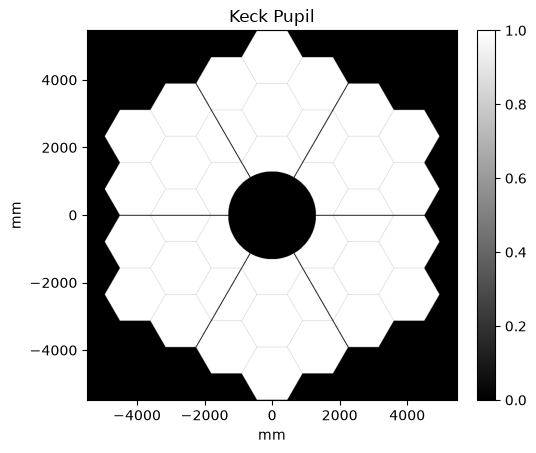

In [3]:
# bandwidth
wvl0 = 0.775 # um
wvls = np.linspace(0.59, 0.96, 25).tolist() # um

# pupil params
d_pupil = 10.95e3 # mm
n_pupil = 1280 # pix; gives 64 or 256 pix/subap for 20x20 or 5x5 lenslets
dx_pupil = d_pupil / n_pupil # mm/pix
r_pupil = 0 # deg
res_ang = np.rad2deg((wvl0 * 1e-6) / (d_pupil * 1e-3)) * 3600 # arcsec/lamD

# pupil grid
xp, yp = make_xy_grid(shape=n_pupil, diameter=d_pupil)
rp, tp = cart_to_polar(xp, yp)
rp_norm = rp / (d_pupil / 2)

# zernikes; piston through spherical noll indexed
nms = [noll_to_nm(n) for n in np.arange(1, 12, 1)]
zernikes = zernike_nm_seq(nms=nms, r=rp_norm, t=tp)
circ = circle(radius=d_pupil / 2, r=rp)

# pupil mask and bases
pupil, segment_windows, segment_bases = keck_primary(xp, yp, rotation=r_pupil) 
pupil *= keck_secondary(xp, yp, rotation=r_pupil)
amp = pupil / np.sqrt(np.sum(pupil ** 2))

# TT removal
ptt = np.stack([np.ones_like(xp), xp, yp], axis=-1)[pupil.astype(bool)]  
R_ptt = np.linalg.pinv(ptt)  
                              
def remove_tt(opd):
    c = R_ptt @ opd[pupil.astype(bool)]
    return opd - (c[0] + c[1] * xp + c[2] * yp)

plt.figure()
plt.imshow(pupil, extent=[xp.min(), xp.max(), yp.min(), yp.max()], cmap='gray')
plt.colorbar(pad=0.04, fraction=0.046)
plt.title('Keck Pupil')
plt.xlabel('mm'); plt.ylabel('mm')


### Transmission/QE Curves

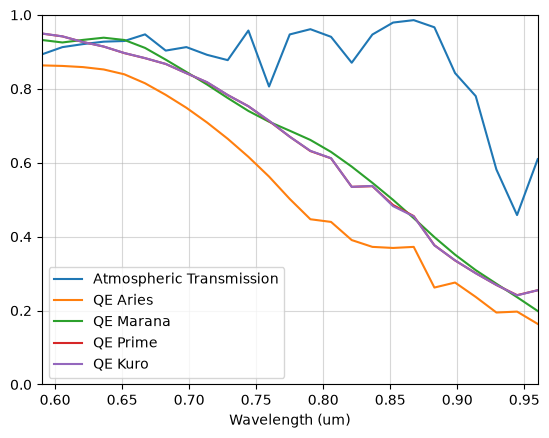

In [18]:
data = np.loadtxt('./data/transmittance_vis_nir.csv', delimiter=',', skiprows=1)
atm_trans = PchipInterpolator(x=data[:, 0], y=data[:, 1])

data = np.loadtxt('./data/qe_aries_6504_pro.csv', delimiter=',', skiprows=1)
qe_aries = PchipInterpolator(x=data[:, 0] / 1e3, y=data[:, 1] / 1e2)

data = np.loadtxt('./data/qe_marana_11.csv', delimiter=',', skiprows=1)
qe_marana = PchipInterpolator(x=data[:, 0] / 1e3, y=data[:, 1] / 1e2)

data = np.loadtxt('./data/qe_prime_95B.csv', delimiter=',', skiprows=1)
qe_prime = PchipInterpolator(x=data[:, 0] / 1e3, y=data[:, 1] / 1e2)

data = np.loadtxt('./data/qe_kuro_1200.csv', delimiter=',', skiprows=1)
qe_kuro = PchipInterpolator(x=data[:, 0] / 1e3, y=data[:, 1] / 1e2)

# throughput vs bandwidth
thrus = atm_trans(wvls) * qe_marana(wvls) / len(wvls)

plt.plot(wvls, atm_trans(wvls), label='Atmospheric Transmission')
plt.plot(wvls, qe_aries(wvls), label='QE Aries')
plt.plot(wvls, qe_marana(wvls), label='QE Marana')
plt.plot(wvls, qe_prime(wvls), label='QE Prime')
plt.plot(wvls, qe_kuro(wvls), label='QE Kuro')
plt.legend()
plt.xlabel('Wavelength (um)')
plt.xlim([0.59, 0.96])
plt.ylim([0, 1])
plt.grid(alpha=0.5)

### "SciCam"
Just for well sampled PSF images.

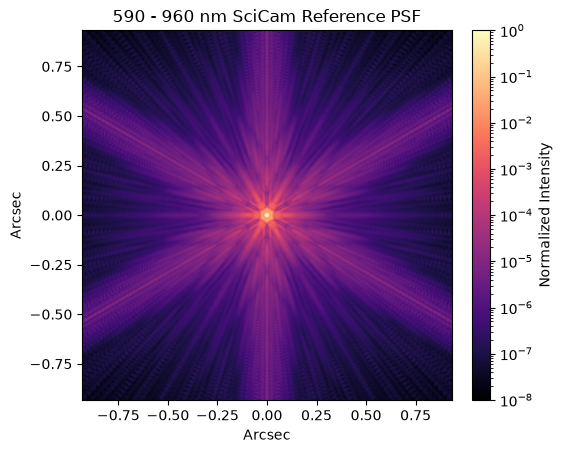

In [6]:
# scicam params
fno_cam = 15 # unitless
efl_cam = fno_cam * d_pupil # mm
n_cam = 512 # pix
dx_cam = 2.9 # um; ~4 pix/lamD
res_cam = wvl0 * fno_cam # um/lamD
fov_cam = n_cam * dx_cam / res_cam * res_ang # arcsec

# scicam grid
xc, yc = make_xy_grid(shape=n_cam, diameter=fov_cam)
rc, tc = cart_to_polar(xc, yc)

# mask for strehl calc
mask_strehl_cam = rc < 1

# mdft propagation executor
ceos_cam = [prepare_executor(pupil_dx=dx_pupil, pupil_samples=n_pupil, focal_dx=dx_cam, 
                             focal_samples=n_cam, wavelength=w, efl=fno_cam * d_pupil, 
                             focal_shift=(dx_cam / 2, dx_cam / 2), kind='mdft')
                             for w in wvls]

# functions
def fwd_cam(opd=None):
    image = 0
    for wvl, ceo, thru in zip(wvls, ceos_cam, thrus):
        wf = Wavefront.from_amp_and_phase(amplitude=amp, phase=opd, 
                                          wavelength=wvl,dx=dx_pupil)
        psf = focus_dft(wavefunction=wf.data, executor=ceo)
        image += np.abs(psf) ** 2 * thru
    return image

def get_strehl(image, reference, mask):
    num = image[mask].max() / image[mask].sum()
    denom = reference[mask].max() / reference[mask].sum()
    return num / denom * 100

def plot_image(data, fov, title, norm='log', cmap='magma', vmin=1e-8):
    plt.figure()
    plt.imshow(data, norm=norm, cmap=cmap, vmin=vmin,
            extent=[-fov / 2, fov / 2, -fov / 2, fov / 2])
    plt.colorbar(pad=0.04, fraction=0.046, label='Normalized Intensity')
    plt.title(title)
    plt.xlabel(r'Arcsec'); plt.ylabel(r'Arcsec')

# ideal reference psf
ref_cam = fwd_cam()

plot_image(ref_cam / ref_cam.max(), fov=fov_cam, 
           title=r'590 - 960 nm SciCam Reference PSF')

### Tracking Optics (TO)
Assuming 0.151 arcsec/pix platescale and effective F/# of 1.45 using the 60 mm Collimating lens and 6 mm C-mount lens combo outlined on slide 12 of [Scott's STRAP upgrade slides](https://keckhawaii.sharepoint.com/:p:/r/sites/Projects/83420-AORefurbishment/Shared%20Documents/02%20TOFU%20(STRAP+LBWFS%20Replacement)/STRAP%20Andor%20Upgrade.pptx?d=wa07785ec263b4345a89029f3d0096947&csf=1&web=1&e=Ed9fX6).

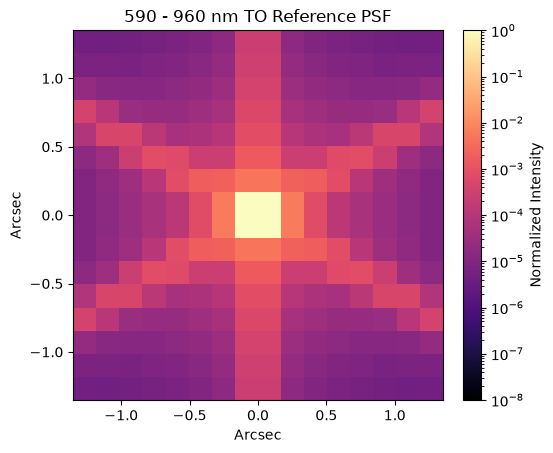

In [7]:
# TO params
fno_to = 1.45 # unitless
efl_to = fno_to * d_pupil # mm
n_to = 16 # pix
dx_to = 13 # um; 
res_to = wvl0 * fno_to # um/lamD
fov_to = n_to * dx_to / res_to * res_ang # arcsec

# TO focal grid
xt, yt = make_xy_grid(shape=n_to, diameter=fov_to)
rt, tt = cart_to_polar(xt, yt)

# mask for strehl calc
mask_strehl_to = rt < 1

# mdft propagation executor
k = 33 # subsamples per pix for nyquist sampling
ceos_to = [prepare_executor(pupil_dx=dx_pupil, pupil_samples=n_pupil, focal_dx=dx_to / k, 
                             focal_samples=n_to * k, wavelength=w, efl=efl_to, 
                             focal_shift=(-(k - 1) / 2 * dx_to / k + dx_to / 2,) * 2,
                             kind='mdft') for w in wvls]

# functions
def fwd_to(opd=None):
    image = 0
    for wvl, ceo, thru in zip(wvls, ceos_to, thrus):
        wf = Wavefront.from_amp_and_phase(amplitude=amp, phase=opd, 
                                          wavelength=wvl,dx=dx_pupil)
        psf = focus_dft(wavefunction=wf.data, executor=ceo)
        image += np.abs(psf) ** 2 * thru
    return bindown(image, k, mode='sum')

# ideal reference psf
ref_to = fwd_to()

plot_image(ref_to / ref_to.max(), fov=fov_to, 
           title=r'590 - 960 nm TO Reference PSF')

### Focus Unit (FU)
Assuming current 5x5 and 20x20 lenslet arrays: 13.5 mm focal length, 0.4 and 1.6 mm lenslet pitch, respectively per slide 9 of [Scott's LBWFS camera upgrade slides](https://keckhawaii.sharepoint.com/:p:/r/sites/Projects/83420-AORefurbishment/Shared%20Documents/02%20TOFU%20(STRAP+LBWFS%20Replacement)/LBWFS%20Camera%20Upgrade%20Opto-mech.pptx?d=w5e660310001046d38dfaaffa3259f79f&csf=1&web=1&e=jENu85).

### 20x20

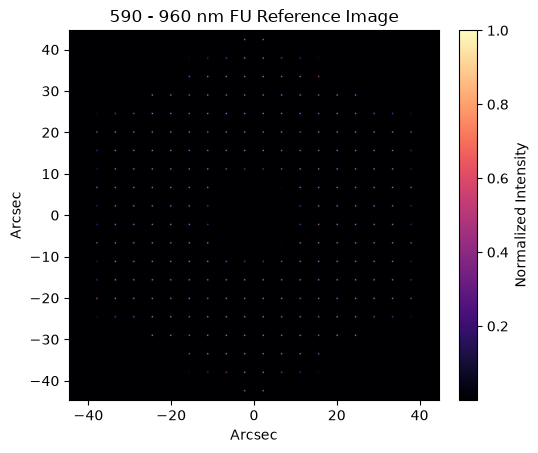

In [93]:
# FU params
n_subap = 20
d_lens = 8 # mm
efl_lens = 13.5 # mm
pitch_lens = d_lens / n_subap # mm
dx_lens = pitch_lens / int(n_pupil / n_subap)
# dx_fu = 11.11 # um
dx_fu = 12.9 # um
# n_fu = 720 # pix
n_fu = 620 # pix
res_fu = wvl0 * efl_lens / (d_lens / n_subap) # um/lamD
fov_fu = n_fu * dx_fu / res_fu * res_ang * n_subap # arcsec

# FU lenslet grid
xl, yl = make_xy_grid(shape=n_pupil, dx=dx_lens)
# lens_screens = [shack_hartmann(pitch=pitch_lens, n=n_subap, efl=efl_lens, wavelength=w, 
#                                x=xl, y=yl, shift=True) for w in wvls]

# FU focal grid
xf, yf = make_xy_grid(shape=n_fu, diameter=fov_fu)
rf, tf = cart_to_polar(xf, yf)

# functions
def lenslet_screen(x, y, pitch, n, efl, wavelength):
    ix = np.clip(np.floor((x + n * pitch / 2) / pitch + 1e-9), 0, n - 1)
    iy = np.clip(np.floor((y + n * pitch / 2) / pitch + 1e-9), 0, n - 1)
    xc = (ix + 0.5 - n / 2) * pitch
    yc = (iy + 0.5 - n / 2) * pitch
    phase = ((x - xc) ** 2 + (y - yc) ** 2) / (2 * efl)
    return np.exp(-2j * np.pi / (wavelength / 1e3) * phase)

lens_screens = [lenslet_screen(xl, yl, pitch_lens, n_subap, efl_lens, w) for w in wvls]

def up_then_down(data, dx_data, dx_new, k=2):
    zoom = dx_data / (dx_new / k)
    # shift by half an upsampled sample so bin edges fall on the lenslet edges
    s = -0.5 / zoom
    fy, fx = [np.fft.fftfreq(n) for n in data.shape]
    ramp = np.exp(-2j * np.pi * s * (fx[None, :] + fy[:, None]))
    data = np.fft.ifft2(np.fft.fft2(data) * ramp).real
    up = fourier_resample(data, zoom)
    dim = (min(up.shape) // (2 * k)) * (2 * k)
    down = bindown(crop_center(up, (dim, dim)), k, mode='sum')
    return np.clip(down, 0, None) / zoom ** 2


def fwd_fu(opd=None):
    image = 0
    for wvl, screen, thru in zip(wvls, lens_screens, thrus):
        wf = Wavefront.from_amp_and_phase(amplitude=amp, phase=opd, 
                                          wavelength=wvl, dx=dx_lens)
        wf *= screen
        wf = wf.free_space(dz=efl_lens)
        image += np.abs(wf.data) ** 2 * thru
    image = up_then_down(image, dx_data=dx_lens * 1e3, dx_new=dx_fu)
    return image

# ideal reference psf
ref_fu = fwd_fu()

plot_image(ref_fu / ref_fu.max(), fov=fov_fu, 
           title=r'590 - 960 nm FU Reference Image',
           norm='linear')

### 5x5

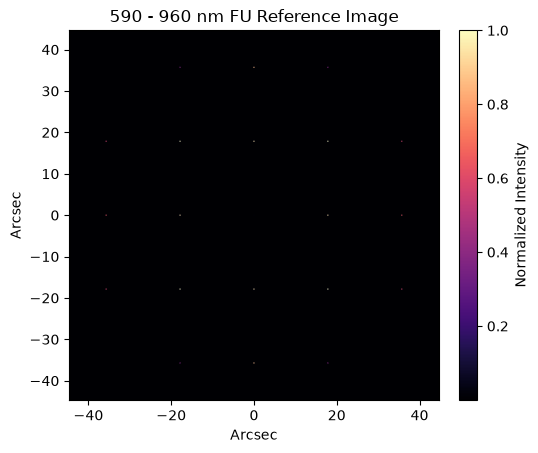

In [90]:
# FU params
n_subap = 5
d_lens = 8 # mm
efl_lens = 13.5 # mm
pitch_lens = d_lens / n_subap # mm
dx_lens = pitch_lens / int(n_pupil / n_subap)
dx_fu = 11.11 # um
# dx_fu = 12.9 # um
n_fu = 720 # pi
# n_fu = 620 # pix
res_fu = wvl0 * efl_lens / (d_lens / n_subap) # um/lamD
fov_fu = n_fu * dx_fu / res_fu * res_ang * n_subap # arcsec

k_fu = 5 # subsamples per pixel; 5x5 spots (~6.5 um) are smaller than a pixel
n_lens = n_pupil // n_subap # pupil samples per subaperture

def make_fwd_fu(dx_fu, n_fu):
    n_win = n_fu // n_subap # detector pix per subaperture
    w = n_win * k_fu
    ceos_fu = [prepare_executor(pupil_dx=dx_lens, pupil_samples=n_lens, focal_dx=dx_fu / k_fu,
                                focal_samples=w, wavelength=wvl, efl=efl_lens,
                                focal_shift=(dx_fu / k_fu / 2,) * 2, kind='mdft')
                                for wvl in wvls]

    def fwd_fu(opd=None):
        image = np.zeros((n_fu * k_fu, n_fu * k_fu))
        for wvl, ceo, thru in zip(wvls, ceos_fu, thrus):
            wf = Wavefront.from_amp_and_phase(amplitude=amp, phase=opd,
                                              wavelength=wvl, dx=dx_lens)
            for i in range(n_subap):
                for j in range(n_subap):
                    lens = wf.data[i * n_lens:(i + 1) * n_lens, j * n_lens:(j + 1) * n_lens]
                    psf = focus_dft(wavefunction=lens, executor=ceo)
                    image[i * w:(i + 1) * w, j * w:(j + 1) * w] += np.abs(psf) ** 2 * thru
        return bindown(image, k_fu, mode='sum')

    return fwd_fu

fwd_fu = make_fwd_fu(dx_fu, n_fu)

# ideal reference psf
ref_fu = fwd_fu()

plot_image(ref_fu / ref_fu.max(), fov=fov_fu, 
           title=r'590 - 960 nm FU Reference Image',
           norm='linear')

### DM

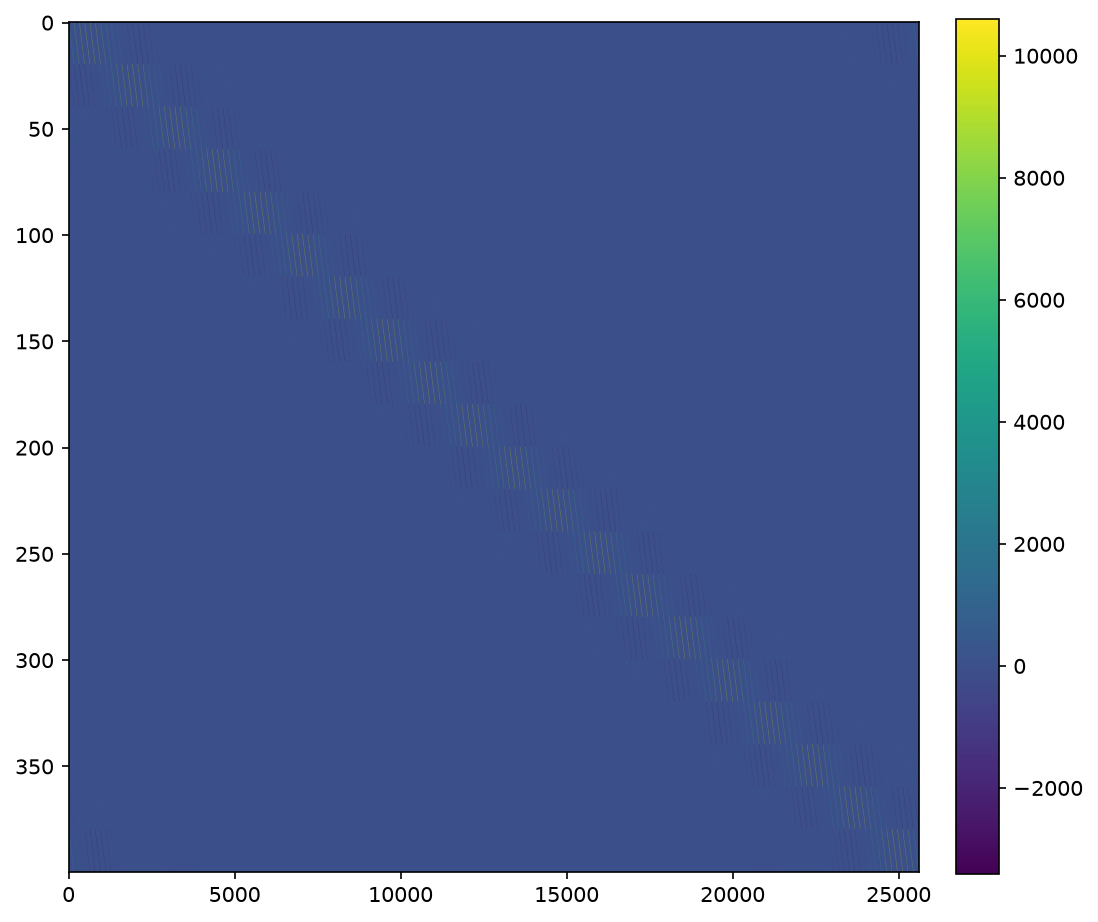

In [9]:
# influence fx (van Dam 2004/KAON 277)
w1 = 2
w2 = -1
sig1 = 0.54 * d_pupil / 20
sig2 = 0.85 * d_pupil / 20
ifx = ((w1 / (2 * np.pi * sig1 **2)) * np.exp(-(xp ** 2 + yp ** 2) / (2 * sig1 ** 2)) + 
       (w2 / (2 * np.pi * sig2 **2)) * np.exp(-(xp ** 2 + yp ** 2) / (2 * sig2 ** 2))) * 0.47 # um

dm = DM(ifn=np.fft.ifftshift(ifx), Nout=n_pupil, Nact=20, sep=int(n_pupil / 20))

# calibrate reconstruction/fitting matrix
step = 8 
sub = (slice(step // 2, None, step),) * 2

dm.actuators[:] = 0
poke_modes = []
for i in range(20):
    for j in range(20):
        dm.actuators[i, j] = 1
        poke = dm.render()[sub].ravel() 
        poke_modes.append(poke)
        dm.actuators[i, j] = 0

A = np.asarray(poke_modes).T # (160 ** 2, 20 ** 2)
R = np.linalg.pinv(A)

plt.figure(figsize=(8, 8), dpi=150)
plt.imshow(R[:,:], aspect=64,)
plt.colorbar(fraction=0.046, pad=0.04)

## Errors
### Segment Phasing
120 nm RMS per Antonin, slightly higher than 100 nm RMS listed in KAPA WFE Budget.

/Users/kderby/src/prysm/prysm/polynomials/fitting.py:29: UserWarning: sum_of_2d_modes weights is a list or tuple: for optimal performance, pre convert to array of shape (k,)
  warnings.warn('sum_of_2d_modes weights is a list or tuple: for optimal performance, pre convert to array of shape (k,)')


Text(0, 0.5, 'mm')

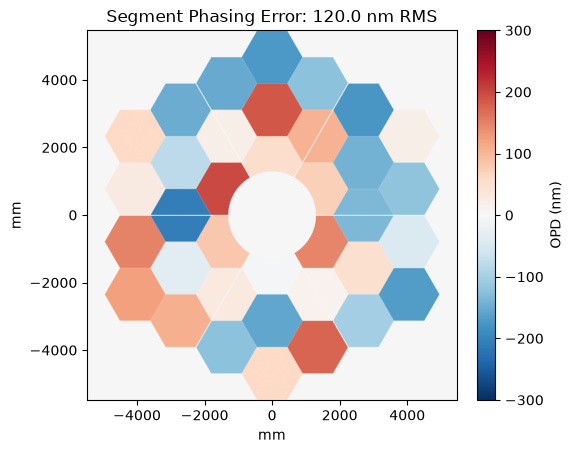

In [10]:
rms_seg = 120 # nm

rng = np.random.default_rng(seed=68)
segment_coefs = [[rng.uniform(-1, 1), 0, 0, 0]
                 for _ in range(len(segment_bases))]
opd_seg = compose_segments(coefs=segment_coefs, windows=segment_windows, 
                           bases=segment_bases, dim=n_pupil)
opd_seg *= rms_seg / np.sqrt(np.mean(opd_seg[pupil.astype(bool)] ** 2))

plt.figure()
plt.imshow(opd_seg * pupil, extent=[xp.min(), xp.max(), yp.min(), yp.max()],
           cmap='RdBu_r', vmin=-300, vmax=300)
plt.colorbar(pad=0.04, fraction=0.046, label='OPD (nm)')
plt.title(f'Segment Phasing Error: {rms(opd_seg, pupil.astype(bool)):.1f} nm RMS')
plt.xlabel('mm'); plt.ylabel('mm')

### Common and Non-Common Path Aberrations
88 nm RMS telescope aberrations + 34 nm RMS DM Errors = 94 nm RSS per KAPA error budget.

~100 nm RMS "pure" NCPAs per Mahawa. Includes 32 nm focus error per KAPA error budget and extra astigmatism which is typically seen per Mahawa/Antonin.

In [11]:
def abc_psd_2d(samples, dx, a, b, c):
    
    df = 1 / (samples * dx / 1e3) # 1/m
    fx = (df * (np.arange(-samples / 2, samples / 2, 1) + 0.5))
    fx, fy = np.meshgrid(fx, fx)
    fr = np.sqrt(fx ** 2 + fy ** 2)

    psd = a / ((1 + ((fr / b) ** 2)) ** (c / 2.))

    return psd, fr

def von_karman_psd_2d(samples, dx, norm, index, outer_scale, inner_scale, surf_rough):

    df = 1 / (samples * dx / 1e3) # 1/m
    fx = (df * (np.arange(-samples / 2, samples / 2, 1) + 0.5))
    fx, fy = np.meshgrid(fx, fx)
    fr = np.sqrt(fx ** 2 + fy ** 2)

    denom = ((1 / outer_scale) ** 2 + fr ** 2) ** (index / 2)
    psd = ((norm / denom) * np.exp(-((fr / inner_scale) ** 2))) + surf_rough

    return psd, fr

def psd_to_opd(psd, seed=727):

    samples = psd.shape[0]

    rng = np.random.RandomState(seed=seed)
    random_phase = rng.rand(samples, samples) * (2 * np.pi) - np.pi

    psd_noisy = np.sqrt(psd ** 2) * np.exp(1.0j * random_phase)

    opd = samples ** 2 * np.fft.ifftshift(np.fft.ifft2(np.fft.ifftshift(psd_noisy))).real
    opd -= np.mean(opd)

    return opd

/Users/kderby/src/prysm/prysm/polynomials/fitting.py:33: UserWarning: sum_of_2d_modes weights dtype mismatched to modes dtype, converting weights to modes' dtype: use same dtype for optimal speed
  warnings.warn("sum_of_2d_modes weights dtype mismatched to modes dtype, converting weights to modes' dtype: use same dtype for optimal speed")


Text(0, 0.5, 'mm')

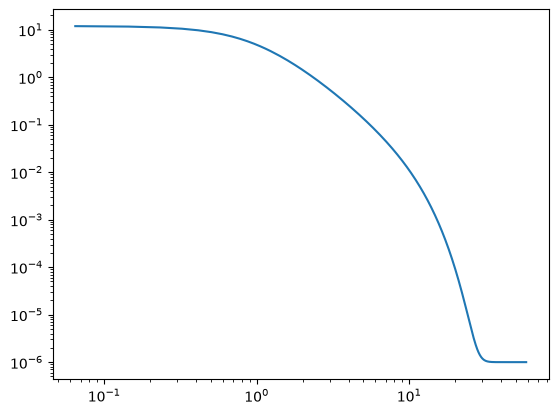

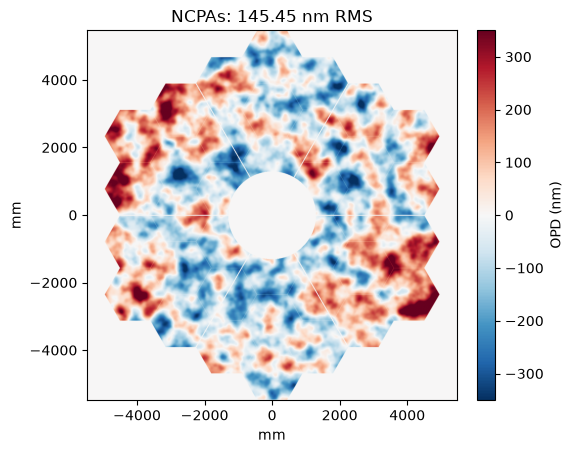

In [12]:
psd_ncpa, fr = von_karman_psd_2d(samples=n_pupil, dx=dx_pupil, norm=12, index=2.6, 
                            outer_scale=1, inner_scale=10, surf_rough=1e-6)

opd_ncpa = psd_to_opd(psd=psd_ncpa, seed=727)
opd_ncpa += sum_of_2d_modes(modes=zernikes[3:6], weights=np.array([50, 50, 50]))
opd_ncpa = remove_tt(opd_ncpa)

plt.figure()
plt.loglog(fr[int(n_pupil / 2), int(n_pupil / 2):], psd_ncpa[int(n_pupil / 2), int(n_pupil / 2):])

plt.figure()
plt.imshow(opd_ncpa * pupil, extent=[xp.min(), xp.max(), yp.min(), yp.max()], 
           cmap='RdBu_r', vmin=-350, vmax=350)
plt.colorbar(pad=0.04, fraction=0.046, label='OPD (nm)')
plt.title(f'NCPAs: {rms(opd_ncpa, pupil.astype(bool)):.2f} nm RMS')
plt.xlabel('mm'); plt.ylabel('mm')

Text(0, 0.5, 'mm')

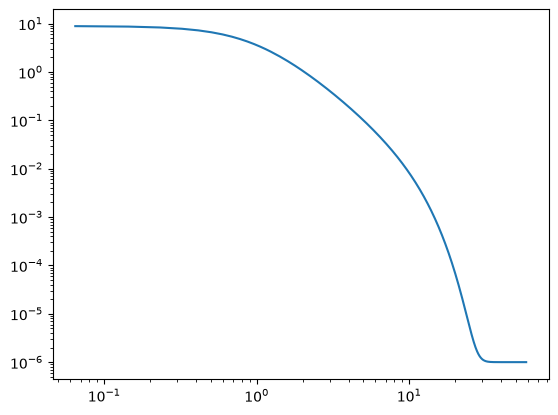

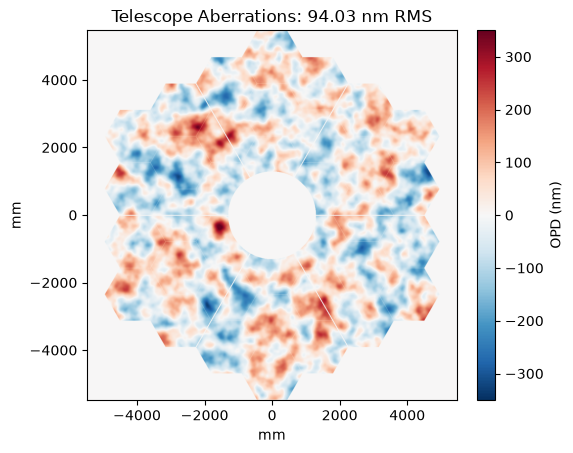

In [13]:
psd_tele, fr = von_karman_psd_2d(samples=n_pupil, dx=dx_pupil, norm=8.9, index=2.6, 
                            outer_scale=1, inner_scale=10, surf_rough=1e-6)

opd_tele = psd_to_opd(psd=psd_tele, seed=67)
opd_tele = remove_tt(opd_tele)

plt.figure()
plt.loglog(fr[int(n_pupil / 2), int(n_pupil / 2):], psd_tele[int(n_pupil / 2), int(n_pupil / 2):])

plt.figure()
plt.imshow(opd_tele * pupil, extent=[xp.min(), xp.max(), yp.min(), yp.max()], 
           cmap='RdBu_r', vmin=-350, vmax=350)
plt.colorbar(pad=0.04, fraction=0.046, label='OPD (nm)')
plt.title(f'Telescope Aberrations: {rms(opd_tele, pupil.astype(bool)):.2f} nm RMS')
plt.xlabel('mm'); plt.ylabel('mm')

## Atmosphere

### Measurement/Fitting Error
130 nm RMS Fitting, 45 nm RMS HO Measurement, and 43 nm RMS HO Aliasing per KAPA WFE budget. RSS together gives 144 nm RMS. 

In [14]:
pupil_grid = make_pupil_grid(dims=n_pupil, diameter=d_pupil / 1e3)
Cn2 = Cn_squared_from_fried_parameter(r0=0.16, wavelength=500e-9)
atm = InfiniteAtmosphericLayer(input_grid=pupil_grid, Cn_squared=Cn2, L0=50, 
                               velocity=7.27, height=0, seed=727)

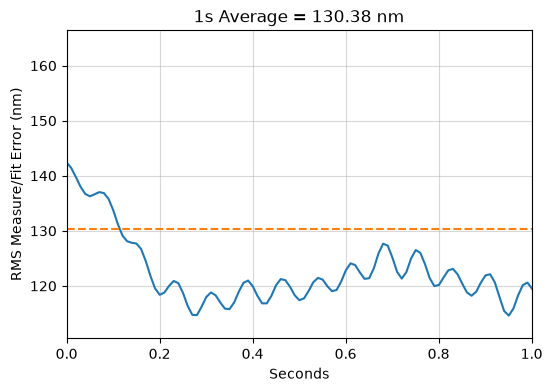

In [ ]:
fit_rms = np.zeros(1000)

atm.reset()
for i in range(1000):
    print(f'Iteration {i + 1:03d}', end='\r')
    atm.evolve_until((i + 1) * 1e-2)
    opd_atm = np.asarray(atm.phase_for(1)).reshape((n_pupil, n_pupil)) / (2 * np.pi) * 1e9

    opd_measure = opd_atm[sub].ravel() 

    command = R @ opd_measure
    dm.actuators = -command.reshape(20, 20)
    opd_dm = dm.render()

    opd_net = opd_atm + opd_dm
    opd_net = remove_tt(opd_net)
    
    fit_rms[i] = rms(opd_net, pupil.astype(bool))
atm.reset()

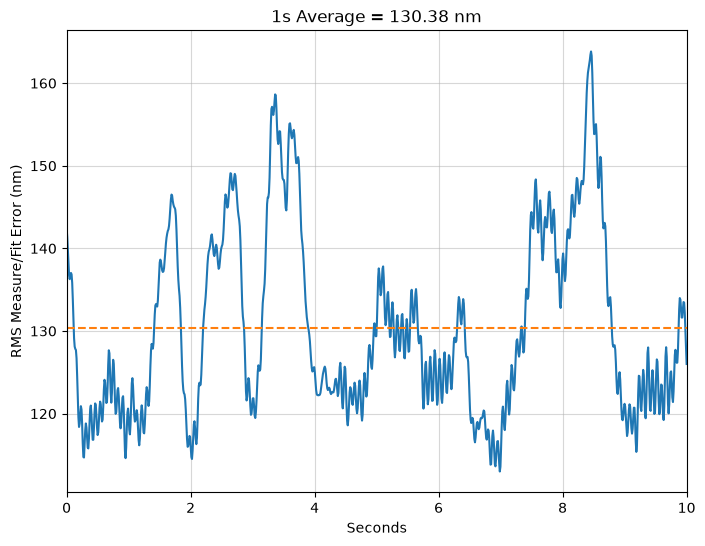

In [662]:
plt.figure(figsize=(8, 6))
plt.plot(np.linspace(0, 10, 1000), fit_rms)
plt.plot(np.linspace(0, 10, 1000), np.ones_like(fit_rms) * np.mean(fit_rms), linestyle='dashed')
plt.xlabel('Seconds'); plt.ylabel('RMS Measure/Fit Error (nm)')
plt.title(f'1s Average = {np.mean(fit_rms):.2f} nm')
plt.xlim([0, 10])
plt.grid(alpha=0.5)

## TO Simulation

In [499]:
from collections import deque
from astropy.io import fits

n_loop = 1000

# burn in
atm.reset()
latency = 3
commands = deque(np.zeros((20, 20)) for _ in range(latency))

for i in range(latency):
    atm.evolve_until(1e-3 * (i + 1))
    opd_atm = np.asarray(atm.phase_for(1)).reshape((n_pupil, n_pupil)) / (2 * np.pi) * 1e9

    opd_measure = opd_atm[sub].ravel() + opd_tele[sub].ravel()

    command = R @ opd_measure
    commands.append(-command.reshape(20, 20))  
    dm.actuators = commands.popleft()
    opd_dm = dm.render()

    opd_net = opd_atm + opd_ncpa + opd_tele + opd_seg + opd_dm
    opd_net = remove_tt(opd_net)

for i in range(n_loop):
    print('Iteration ' + str(i + 1), end='\r')
    
    atm.evolve_until(1e-3 * (i + 1 + latency))
    opd_atm = np.asarray(atm.phase_for(1)).reshape((n_pupil, n_pupil)) / (2 * np.pi) * 1e9

    opd_measure = opd_atm[sub].ravel() + opd_tele[sub].ravel()
    
    command = R @ opd_measure
    commands.append(-command.reshape(20, 20))
    dm.actuators = commands.popleft()
    opd_dm = dm.render()

    opd_net = opd_atm + opd_ncpa + opd_tele + opd_seg + opd_dm
    opd_net = remove_tt(opd_net)

    img_to = fwd_to(opd=opd_net)

    fits.writeto(f'./data/to_teledyne/im_{i + 1:04d}.fits', data=img_to, overwrite=True)

## FU Simulation

### Generate Images

In [22]:
from collections import deque
from astropy.io import fits

n_loop = 1000

# burn in
atm.reset()
latency = 3
commands = deque(np.zeros((20, 20)) for _ in range(latency))

for i in range(latency):
    atm.evolve_until(1e-3 * (i + 1))
    opd_atm = np.asarray(atm.phase_for(1)).reshape((n_pupil, n_pupil)) / (2 * np.pi) * 1e9

    opd_measure = opd_atm[sub].ravel() + opd_tele[sub].ravel()

    command = R @ opd_measure
    commands.append(-command.reshape(20, 20))  
    dm.actuators = commands.popleft()
    opd_dm = dm.render()

    opd_net = opd_atm + opd_ncpa + opd_tele + opd_seg + opd_dm
    opd_net = remove_tt(opd_net)

for i in range(n_loop):
    print('Iteration ' + str(i + 1), end='\r')
    
    atm.evolve_until(1e-3 * (i + 1 + latency))
    opd_atm = np.asarray(atm.phase_for(1)).reshape((n_pupil, n_pupil)) / (2 * np.pi) * 1e9

    opd_measure = opd_atm[sub].ravel() + opd_tele[sub].ravel()
    
    command = R @ opd_measure
    commands.append(-command.reshape(20, 20))
    dm.actuators = commands.popleft()
    opd_dm = dm.render()

    opd_net = opd_atm + opd_ncpa + opd_tele + opd_seg + opd_dm
    opd_net = remove_tt(opd_net)

    img_fu = fwd_fu(opd=opd_net)

    fits.writeto(f'./data/fu_5_marana/im_{i + 1:04d}.fits', data=img_fu, overwrite=True)

In [ ]:
from collections import deque
from astropy.io import fits

n_loop = 1000

# burn in
atm.reset()
latency = 3
commands = deque(np.zeros((20, 20)) for _ in range(latency))

for i in range(latency):
    atm.evolve_until(1e-3 * (i + 1))
    opd_atm = np.asarray(atm.phase_for(1)).reshape((n_pupil, n_pupil)) / (2 * np.pi) * 1e9

    opd_measure = opd_atm[sub].ravel() + opd_tele[sub].ravel()

    command = R @ opd_measure
    commands.append(-command.reshape(20, 20))  
    dm.actuators = commands.popleft()
    opd_dm = dm.render()

    opd_net = opd_atm + opd_ncpa + opd_tele + opd_seg + opd_dm
    opd_net = remove_tt(opd_net)

defocus_vals = []

for i in range(n_loop):
    print('Iteration ' + str(i + 1), end='\r')
    
    atm.evolve_until(1e-3 * (i + 1 + latency))
    opd_atm = np.asarray(atm.phase_for(1)).reshape((n_pupil, n_pupil)) / (2 * np.pi) * 1e9

    opd_measure = opd_atm[sub].ravel() + opd_tele[sub].ravel()
    
    command = R @ opd_measure
    commands.append(-command.reshape(20, 20))
    dm.actuators = commands.popleft()
    opd_dm = dm.render()

    opd_net = opd_atm + opd_ncpa + opd_tele + opd_seg + opd_dm
    opd_net = remove_tt(opd_net)

    defocus_vals.append(lstsq(modes=modes_keck, data=opd_net)[2])

fits.writeto(f'./data/defocus_vals.fits', data=np.array(defocus_vals), overwrite=True)

## FU Performance

### Functions

In [60]:
def pupil_modes(noll):
    """Zernikes orthonormalized over the Keck pupil, scaled to 1 nm RMS."""
    m = pupil.astype(bool)
    Z = np.stack([zernikes[n - 1][m] for n in [1, *noll]], axis=1)
    Q, _ = np.linalg.qr(Z)
    Q *= np.sqrt(m.sum())
    modes = np.zeros((len(noll), *pupil.shape))
    modes[:, m] = Q[:, 1:].T
    return modes

def get_centroids(image, n_subap, pxscl, radius=0.5, thresh=0.5, bkg=0, centers=None):
    """Centroid every subaperture of a Shack-Hartmann image.

    Parameters
    ----------
    image : ndarray
        square detector image, n_subap lenslets across
    n_subap : int
        number of lenslets across the image
    pxscl : float
        detector pixel scale, arcsec/pix
    radius : float or None
        1-sigma radius of the Gaussian weighting, arcsec; None gives an
        unweighted centroid over the whole subaperture
    thresh : float
        reject subapertures whose flux is below this fraction of the
        brightest subaperture's flux
    bkg : float or ndarray
        background (bias, dark, sky) subtracted before centroiding
    centers : tuple of ndarray, optional
        (cx, cy) weight centres in pixels of the full image, shape
        (n_subap, n_subap); defaults to the centre of each subaperture

    Returns
    -------
    cx, cy : ndarray
        shape (n_subap, n_subap), centroids in pixels of the full image,
        NaN where rejected
    illum : ndarray
        shape (n_subap, n_subap), weighted flux relative to the brightest subaperture

    """
    im = np.clip(image - bkg, 0, None)
    edges = np.round(np.linspace(0, im.shape[0], n_subap + 1)).astype(int)
    rows, cols = np.indices(im.shape)
    if radius is not None:
        sig = radius / pxscl # pix

    flux = np.zeros((n_subap, n_subap))
    cx = np.full((n_subap, n_subap), np.nan)
    cy = np.full((n_subap, n_subap), np.nan)
    for i in range(n_subap):
        for j in range(n_subap):
            win = (slice(edges[i], edges[i + 1]), slice(edges[j], edges[j + 1]))
            sub = im[win]
            if radius is not None:
                if centers is None:
                    x0 = (edges[j] + edges[j + 1] - 1) / 2
                    y0 = (edges[i] + edges[i + 1] - 1) / 2
                else:
                    x0, y0 = centers[0][i, j], centers[1][i, j]
                r2 = (cols[win] - x0) ** 2 + (rows[win] - y0) ** 2
                sub = sub * np.exp(-r2 / (2 * sig ** 2))
            flux[i, j] = sub.sum()
            if flux[i, j] > 0:
                cx[i, j] = np.sum(sub * cols[win]) / flux[i, j]
                cy[i, j] = np.sum(sub * rows[win]) / flux[i, j]

    illum = flux / flux.max()
    cx[illum < thresh] = np.nan
    cy[illum < thresh] = np.nan
    return cx, cy, illum


def calibrate_defocus(fwd, n_subap, pxscl, radius=0.5, amp_nm=100, thresh=0.5,
                      noll=range(2, 12)):
    """Push-pull calibrate the FU and return a modal reconstructor.

    Parameters
    ----------
    fwd : callable
        fwd(opd) -> FU image, opd in nm
    n_subap : int
        lenslets across, 20 or 5
    pxscl : float
        detector pixel scale, arcsec/pix
    radius : float or None
        1-sigma radius of the Gaussian centroid weighting, arcsec
    amp_nm : float
        RMS amplitude of each push/pull
    thresh : float
        illumination threshold for valid subapertures, passed to get_centroids
    noll : iterable of int
        Noll modes fit jointly

    Returns
    -------
    R : ndarray
        shape (len(noll), n_slopes); R @ slopes(image) = RMS nm of each mode
    slopes : callable
        slopes(image, bkg=0) -> centroid offsets from the reference, valid
        subaps only, using the same pxscl and radius as the calibration
    modes : ndarray
        the 1 nm RMS pupil modes, one per row of R

    """
    noll = list(noll)
    modes = pupil_modes(noll)
    ref = fwd()
    cx_ref, cy_ref, _ = get_centroids(ref, n_subap, pxscl, radius=radius, thresh=thresh)
    valid = ~np.isnan(cx_ref)
    # centre the Gaussian weights on the reference spots, not the window centres
    edges = np.round(np.linspace(0, ref.shape[0], n_subap + 1)).astype(int)
    mid = (edges[:-1] + edges[1:] - 1) / 2
    centers = (np.where(valid, cx_ref, mid[None, :]), np.where(valid, cy_ref, mid[:, None]))
    cx_ref, cy_ref, _ = get_centroids(ref, n_subap, pxscl, radius=radius, thresh=0, centers=centers)

    def slopes(image, bkg=0):
        cx, cy, _ = get_centroids(image, n_subap, pxscl, radius=radius, thresh=0, bkg=bkg, centers=centers)
        return np.concatenate([(cx - cx_ref)[valid], (cy - cy_ref)[valid]])


    S = np.empty((2 * valid.sum(), len(noll)))
    for i, mode in enumerate(modes):
        S[:, i] = (slopes(fwd(amp_nm * mode)) - slopes(fwd(-amp_nm * mode))) / (2 * amp_nm)

    R = np.linalg.pinv(S)
    return R, slopes, modes


### Calibration

In [64]:
# 13 um pixels for aries camera
dx_fu = 12.9 # um
n_fu = 620 # pix
res_fu = wvl0 * efl_lens / (d_lens / n_subap) # um/lamD
fov_fu = n_fu * dx_fu / res_fu * res_ang * n_subap # arcsec

pxscl_fu_13 = fov_fu / n_fu

R_fu_13, slopes_fu_13, modes_keck = calibrate_defocus(make_fwd_fu(12.9, 620), n_subap, pxscl_fu_13)

# 11 um pixels for other cameras
dx_fu = 11.11 # um
n_fu = 720 # pix
res_fu = wvl0 * efl_lens / (d_lens / n_subap) # um/lamD
fov_fu = n_fu * dx_fu / res_fu * res_ang * n_subap # arcsec

pxscl_fu_11 = fov_fu / n_fu

R_fu_11, slopes_fu_11, _ = calibrate_defocus(make_fwd_fu(11.11, 720), n_subap, pxscl_fu_11)

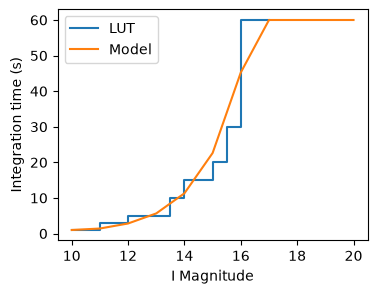

In [65]:
# Create model for LBWFS integration time lookup
lbwfs_lut = np.array([[10.0 ,1.], [11.0 ,1.], [11.0 ,3.], [12.0 ,3.], [12.0 ,5.], [13.5, 5.], \
                    [13.5, 10.], [14.0, 10.], [14.0, 15.], [15.0, 15.], [15.0, 20.], [15.5, 20.], \
                    [15.5, 30.], [16.0, 30.], [16.0, 60.], [17.0, 60.]])

def lbwfs_frrt(mag):
    frrt = np.clip(2**(1.0*(mag-10.5)), 1.0, 60.)
    #frrt = np.clip(2**(1.0*(mag-10.5)), 1.0, None)
    return frrt

#print(f"Mag:   {strap_lut[:,0]+0.5}")
#print(f"LUT:   {strap_lut[:,1]}")
#print(f"Model: {frrt_model(strap_lut[:,0]+0.5).astype(int)}")

mag_vec = np.linspace(10,20,11)
plt.figure(figsize=(4, 3))
plt.plot(lbwfs_lut[:,0], lbwfs_lut[:,1], label="LUT")
plt.plot(mag_vec, lbwfs_frrt(mag_vec), label="Model")
plt.xlabel("I Magnitude")
plt.ylabel("Integration time (s)")
plt.legend()
plt.show()

In [66]:
cams = {
    'Ideal':        {"read_noise": 0.0,    "dark_curr": 0.000,   "qe": 1.00},
    'Aries 6504P' : {"read_noise": 0.875,  "dark_curr": 0.050,   "qe": 0.60},
    'KURO 1200B' :  {"read_noise": 1.68,   "dark_curr": 0.883,   "qe": 0.72},
    'Prime 95B' :   {"read_noise": 1.71,   "dark_curr": 0.475,   "qe": 0.73},
    'Marana 11' :   {"read_noise": 1.596,  "dark_curr": 0.662,   "qe": 0.72},
}

# Photometry (DAVINCI zeropoints from KAON 764)
# The detector quantum efficiencies used ... are the minimum for a Hawaii-4RG detector (Adkins, 2009a).
def opt_phot(mag):
    """
    Compute photon flux at detector

    Args:
        mag (float): Star magnitude in I/Z 

    Returns:
        float: Photon flux at detector (photons/s)
    """

    zpt_I = 27.34 # I band (700-854 nm) photometric zeropoint
    zpt_Z = 27.16 # Z band (855-962 nm) photometric zeropoint
    qe = 0.70 # TBC
    phot_I = 10 ** (-0.4 * (mag-zpt_I)) / qe
    phot_Z = 10 ** (-0.4 * (mag-zpt_Z)) / qe

    return phot_I + phot_Z

def opt_bkg():
    """
    Compute sky photon flux at detector

    Args:
        none

    Returns:
        float: Photon flux at detector (photons/s/arcsec^2)
    """

    bkg_I = 19.33 # I band (700-854 nm) sky brightness
    bkg_Z = 18.45 # Z band (855-962 nm) sky brightness
    zpt_I = 27.34 # I band (700-854 nm) photometric zeropoint
    zpt_Z = 27.16 # Z band (855-962 nm) photometric zeropoint
    qe = 0.70 # TBC
    phot_I = 10 ** (-0.4 * (bkg_I-zpt_I)) / qe
    phot_Z = 10 ** (-0.4 * (bkg_Z-zpt_Z)) / qe

    return phot_I + phot_Z

def add_noise(n_stack, image, pxscl, texp, mag, camera, bs, debug=False):

    read_noise = camera['read_noise'] # e-/frame
    dark_current = camera['dark_curr'] # e-/s/pix
    qe = camera['qe'] # e-/photon
    
    flux_psf = opt_phot(mag) * bs * texp # phot/s
    flux_sky = opt_bkg() * bs # phot/s/arcsec^2
    flux_sky *= pxscl ** 2 # phot/s

    noisy_imgs = np.repeat(image[:, :, np.newaxis], repeats=n_stack, axis=2)
    noisy_imgs = noisy_imgs * flux_psf
    noisy_imgs += np.ones_like(noisy_imgs) * ((dark_current + flux_sky) * texp)

    noisy_imgs = np.random.poisson(noisy_imgs).astype('float64')
    noisy_imgs += np.random.normal(scale=read_noise, size=noisy_imgs.shape)

    if debug:
        print(f'PSF flux: {flux_psf:.2f} photons')
        print(f'Sky flux: {flux_sky:.2f} photons/pix')
        box_sum = noisy_imgs[:, :, 100].sum()
        print(f'Image Sum (16x16): {box_sum.mean():.2f}')

    return noisy_imgs

### 20x20

In [54]:
defocus_true = fits.getdata('./data/defocus_vals.fits').mean()
n_stack = 500
bs = 0.1
results_fu = {}

for cam in cams:
    print(cam)

    defocus_errs = np.zeros_like(mag_vec)

    if cam == 'Aries 6504P':
        folder = 'fu_20_aries'
        slopes_fu = slopes_fu_13
        R_fu = R_fu_13
        pxscl = pxscl_fu_13
    elif cam == 'Marana 11':
        folder = 'fu_20_marana'
        slopes_fu = slopes_fu_11
        R_fu = R_fu_11
        pxscl = pxscl_fu_11
    else:
        folder = 'fu_20_teledyne'
        slopes_fu = slopes_fu_11
        R_fu = R_fu_11
        pxscl = pxscl_fu_11
    long_exp_fu = 0
    for i in range(1000):
        long_exp_fu += fits.getdata(f'./data/' + folder + f'/im_{i + 1:04d}.fits') / 1000
    if cam == 'Ideal':
        long_exp_fu /= long_exp_fu.sum()

    g = (R_fu @ slopes_fu(long_exp_fu))[2] / defocus_true

    for i, mag in enumerate(mag_vec):
        print(mag, end='\r')
        texp = lbwfs_frrt(mag)

        flux_sky_per_pix = opt_bkg() * bs
        flux_sky_per_pix *= pxscl ** 2 
        bkg = (cams[cam]['dark_curr'] + flux_sky_per_pix) * texp

        ims_noisy = add_noise(n_stack=n_stack, image=long_exp_fu, pxscl=pxscl, 
                            texp=texp, mag=mag, camera=cams[cam], bs=bs)
        
        defocus_err = np.zeros(n_stack)
        for j in range(n_stack):
            im = ims_noisy[:, :, j] - bkg
            defocus_measured = (R_fu @ slopes_fu(im))[2] / g
            defocus_err[j] = defocus_measured - defocus_true

        defocus_errs[i] = np.sqrt(np.mean(defocus_err ** 2))
        
    results_fu.update({cam : defocus_errs})

Ideal
Aries 6504P
KURO 1200B
Prime 95B
Marana 11


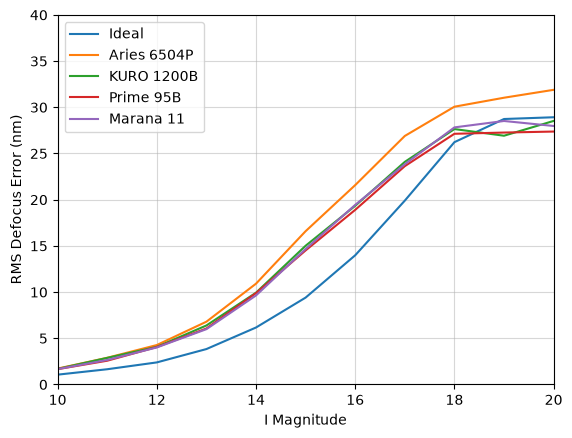

In [55]:
for cam in results_fu:
    plt.plot(mag_vec, results_fu[cam], label=cam)
plt.xlabel('I Magnitude')
plt.ylabel('RMS Defocus Error (nm)')
plt.ylim([0, 40])
plt.xlim([10, 20])
plt.grid(alpha=0.5)
plt.legend()

### 5x5

In [67]:
defocus_true = fits.getdata('./data/defocus_vals.fits').mean()
n_stack = 500
bs = 0.1
results_fu = {}

for cam in cams:
    print(cam)

    defocus_errs = np.zeros_like(mag_vec)

    if cam == 'Aries 6504P':
        folder = 'fu_5_aries'
        slopes_fu = slopes_fu_13
        R_fu = R_fu_13
        pxscl = pxscl_fu_13
    elif cam == 'Marana 11':
        folder = 'fu_5_marana'
        slopes_fu = slopes_fu_11
        R_fu = R_fu_11
        pxscl = pxscl_fu_11
    else:
        folder = 'fu_5_marana'
        slopes_fu = slopes_fu_11
        R_fu = R_fu_11
        pxscl = pxscl_fu_11
    long_exp_fu = 0
    for i in range(1000):
        long_exp_fu += fits.getdata(f'./data/' + folder + f'/im_{i + 1:04d}.fits') / 1000
    if cam == 'Ideal':
        long_exp_fu /= long_exp_fu.sum()

    g = (R_fu @ slopes_fu(long_exp_fu))[2] / defocus_true

    for i, mag in enumerate(mag_vec):
        print(mag, end='\r')
        texp = lbwfs_frrt(mag)

        flux_sky_per_pix = opt_bkg() * bs
        flux_sky_per_pix *= pxscl ** 2 
        bkg = (cams[cam]['dark_curr'] + flux_sky_per_pix) * texp

        ims_noisy = add_noise(n_stack=n_stack, image=long_exp_fu, pxscl=pxscl, 
                            texp=texp, mag=mag, camera=cams[cam], bs=bs)
        
        defocus_err = np.zeros(n_stack)
        for j in range(n_stack):
            im = ims_noisy[:, :, j] - bkg
            defocus_measured = (R_fu @ slopes_fu(im))[2] / g
            defocus_err[j] = defocus_measured - defocus_true

        defocus_errs[i] = np.sqrt(np.mean(defocus_err ** 2))
        
    results_fu.update({cam : defocus_errs})

Ideal
Aries 6504P
KURO 1200B
Prime 95B
Marana 11


In [69]:
rmag0 = 19.0 # Magnitude at which performance is normalized
fo_rmag0 = 50 # nm focus error at rmag0
fo_exp = 0.20 # exponent slope
fo_floor = 12.5 # nm floor focus error
tt_rmag0 = 40. # mas RMS focus error at rmag0
tt_exp = 0.43 # exponent slope
tt_floor = 2.5 # mas floor TT error

var_tt = np.clip(tt_rmag0**2 * 10**(tt_exp*(mag_vec-rmag0)), tt_floor**2, None)
var_fo = np.clip(fo_rmag0**2 * 10**(fo_exp*(mag_vec-rmag0)), fo_floor**2, None)

loop_gain = 0.5
err_tt = var_tt**0.5 / loop_gain
err_fo = var_fo**0.5 / loop_gain

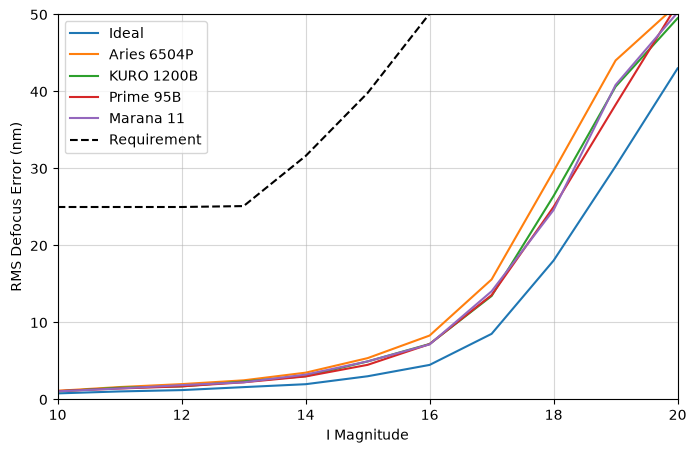

In [73]:
plt.figure(figsize=(8, 5))
for cam in results_fu:
    plt.plot(mag_vec, results_fu[cam], label=cam)
plt.plot(mag_vec, err_fo, label='Requirement', color='k', linestyle='dashed')
plt.xlabel('I Magnitude')
plt.ylabel('RMS Defocus Error (nm)')
plt.ylim([0, 50])
plt.xlim([10, 20])
plt.grid(alpha=0.5)
plt.legend()

In [78]:
cols = list(results_fu)
data = np.column_stack([mag_vec] + [results_fu[cam] for cam in cols])
np.savetxt('./data/FU_5x5_bs_10.csv', data, delimiter=',', fmt='%.6g',
           header=','.join(['mag'] + cols), comments='')

In [82]:
with open('./data/FU_5x5_bs_10.csv') as f:
    cols = f.readline().strip().split(',')
data = np.loadtxt('./data/FU_5x5_bs_10.csv', delimiter=',', skiprows=1)

mag_vec = data[:, 0]
data_5x5 = {cam: data[:, i] for i, cam in enumerate(cols[1:], start=1)}

with open('./data/FU_20x20_bs_10.csv') as f:
    cols = f.readline().strip().split(',')
data = np.loadtxt('./data/FU_20x20_bs_10.csv', delimiter=',', skiprows=1)

mag_vec = data[:, 0]
data_20x20 = {cam: data[:, i] for i, cam in enumerate(cols[1:], start=1)}

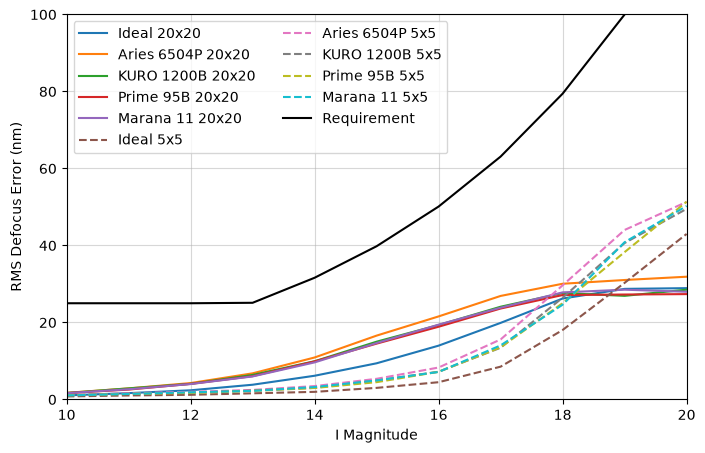

In [89]:
plt.figure(figsize=(8, 5))
for cam in data_20x20:
    plt.plot(mag_vec, data_20x20[cam], label=cam + ' 20x20')
for cam in data_5x5:
    plt.plot(mag_vec, data_5x5[cam], label=cam + ' 5x5', linestyle='dashed')
plt.plot(mag_vec, err_fo, label='Requirement', color='k')
plt.xlabel('I Magnitude')
plt.ylabel('RMS Defocus Error (nm)')
plt.ylim([0, 100])
plt.xlim([10, 20])
plt.grid(alpha=0.5)
plt.legend(ncols=2, loc='upper left')

## All Together

In [419]:
rms(opd_net, pupil.astype(bool))

OldStyleField(195.52265973)

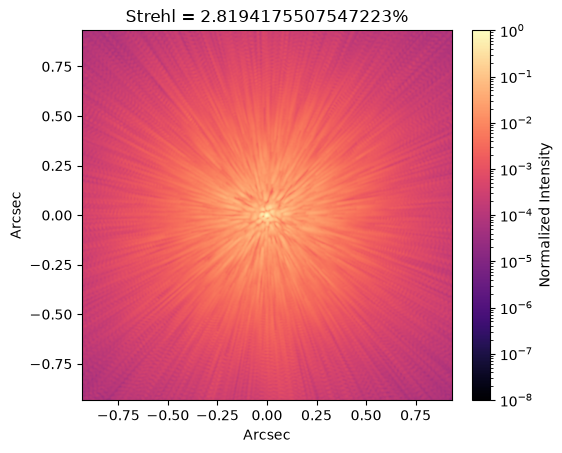

In [440]:
opd_measure = (opd_atm[sub].ravel() + 
               opd_tele[sub].ravel())
command = R @ opd_measure
dm.actuators = -command.reshape(20, 20)
opd_dm = dm.render()

opd_net = opd_atm + opd_ncpa + opd_tele + opd_seg + opd_dm
opd_net = remove_tt(opd_net)

img_cam = fwd_cam(opd=opd_net)

plot_image(img_cam / img_cam.max(), fov=fov_cam,
           title=f'Strehl = {get_strehl(img_cam, ref_cam, mask=mask_strehl_cam):2}%')

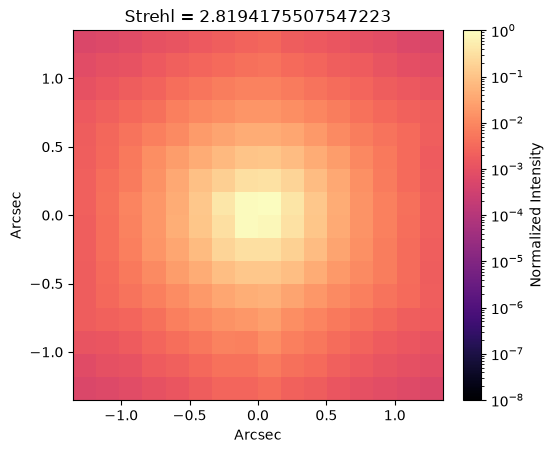

In [441]:
img_to = fwd_to(opd=opd_net)

plot_image(img_to / img_to.max(), fov=fov_to,
           title=f'Strehl = {get_strehl(img_cam, ref_cam, mask=mask_strehl_cam)}')

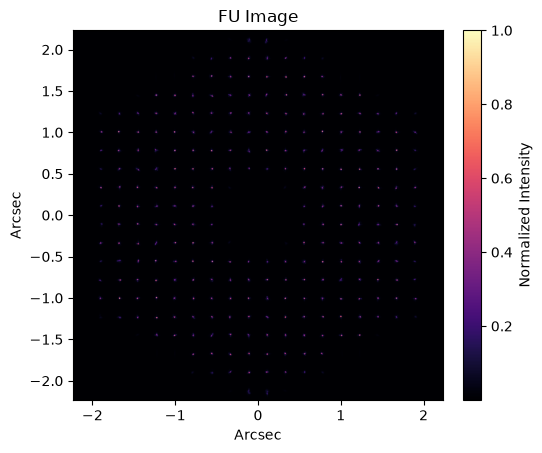

In [448]:
img_fu = fwd_fu(opd=opd_net)

plot_image(img_fu / img_fu.max(), fov=fov_fu, norm='linear',
           title=r'FU Image',)

### Animation

In [345]:
from matplotlib.animation import FuncAnimation, PillowWriter, FFMpegWriter

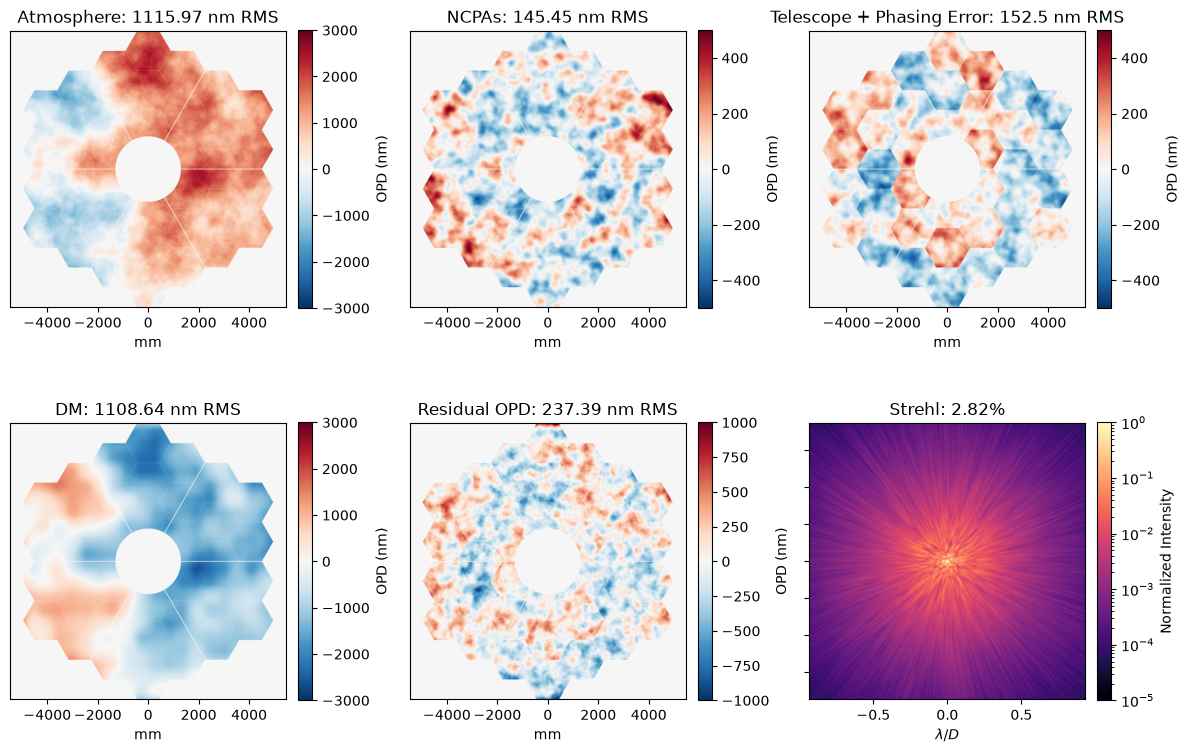

In [449]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(12, 8))

ax_seg = axs[0, 2]
im_seg = ax_seg.imshow((opd_seg + opd_tele) * pupil, extent=[xp.min(), xp.max(), yp.min(), yp.max()], origin='lower',
           cmap='RdBu_r', vmin=-500, vmax=500)
plt.colorbar(im_seg, pad=0.04, fraction=0.046, label='OPD (nm)')
ax_seg.set_title(f'Telescope + Phasing Error: {rms(opd_seg + opd_tele, pupil.astype(bool)):.1f} nm RMS')
ax_seg.set_xlabel('mm'); ax_seg.set_yticks([])

ax_ncpa = axs[0, 1]
im_ncpa = ax_ncpa.imshow(opd_ncpa * pupil, extent=[xp.min(), xp.max(), yp.min(), yp.max()], origin='lower',
           cmap='RdBu_r', vmin=-500, vmax=500)
plt.colorbar(im_ncpa, pad=0.04, fraction=0.046, label='OPD (nm)')
ax_ncpa.set_title(f'NCPAs: {np.sqrt(np.mean(opd_ncpa[pupil.astype(bool)] ** 2)):.2f} nm RMS')
ax_ncpa.set_xlabel('mm'); ax_ncpa.set_yticks([])

ax_atm = axs[0, 0]
im_atm = ax_atm.imshow((opd_atm) * pupil, extent=[xp.min(), xp.max(), yp.min(), yp.max()], origin='lower',
           cmap='RdBu_r', vmin=-3e3, vmax=3e3)
plt.colorbar(im_atm, pad=0.04, fraction=0.046, label='OPD (nm)')
ax_atm.set_title(f'Atmosphere: {rms(opd_atm, pupil.astype(bool)):.2f} nm RMS')
ax_atm.set_xlabel('mm'); ax_atm.set_yticks([])

ax_dm = axs[1, 0]
im_dm = ax_dm.imshow(opd_dm * pupil, extent=[xp.min(), xp.max(), yp.min(), yp.max()], origin='lower',
           cmap='RdBu_r', vmin=-3e3, vmax=3e3)
plt.colorbar(im_dm, pad=0.04, fraction=0.046, label='OPD (nm)')
ax_dm.set_title(f'DM: {np.sqrt(np.mean(opd_dm[pupil.astype(bool)] ** 2)):.2f} nm RMS')
ax_dm.set_xlabel('mm'); ax_dm.set_yticks([])

opd_net = opd_atm + opd_ncpa + opd_tele + opd_seg + opd_dm
ax_net = axs[1, 1]
im_net = ax_net.imshow(opd_net * pupil, extent=[xp.min(), xp.max(), yp.min(), yp.max()], origin='lower',
           cmap='RdBu_r', vmin=-1e3, vmax=1e3)
plt.colorbar(im_net, pad=0.04, fraction=0.046, label='OPD (nm)')
ax_net.set_title(f'Residual OPD: {np.sqrt(np.mean(opd_net[pupil.astype(bool)] ** 2)):.2f} nm RMS')
ax_net.set_xlabel('mm'); ax_net.set_yticks([])

ax_psf = axs[1, 2]
im_psf = ax_psf.imshow(img_cam / img_cam.max(), extent=[-fov_cam / 2, fov_cam / 2, -fov_cam / 2, fov_cam / 2], 
           norm='log', cmap='magma', vmin=1e-5)
plt.colorbar(im_psf, pad=0.04, fraction=0.046, label='Normalized Intensity')
ax_psf.set_title(f'Strehl: {get_strehl(img_cam, ref_cam, mask_strehl_cam):.2f}%')
ax_psf.set_xlabel(r'$\lambda/D$'); ax_psf.set_yticklabels([])

fig.tight_layout()

In [452]:
from collections import deque

# burn in
atm.reset()
latency = 3
commands = deque(np.zeros((20, 20)) for _ in range(latency))

for i in range(latency):
    atm.evolve_until(1e-3 * (i + 1))
    opd_atm = np.asarray(atm.phase_for(1)).reshape((n_pupil, n_pupil)) / (2 * np.pi) * 1e9

    opd_measure = opd_atm[sub].ravel() + opd_tele[sub].ravel()

    command = R @ opd_measure
    commands.append(-command.reshape(20, 20))
    dm.actuators = commands.popleft()
    opd_dm = dm.render()

    opd_net = opd_atm + opd_ncpa + opd_tele + opd_seg + opd_dm
    opd_net = remove_tt(opd_net)

def update(i):
    atm.evolve_until(1e-3 * (i + 1 + latency))
    opd_atm = np.asarray(atm.phase_for(1)).reshape((n_pupil, n_pupil)) / (2 * np.pi) * 1e9

    opd_measure = opd_atm[sub].ravel() + opd_tele[sub].ravel()
    
    command = R @ opd_measure
    commands.append(-command.reshape(20, 20))
    dm.actuators = commands.popleft()
    opd_dm = dm.render()

    opd_net = opd_atm + opd_ncpa + opd_tele + opd_seg + opd_dm
    opd_net = remove_tt(opd_net)

    img_cam = fwd_cam(opd=opd_net)

    im_atm.set_data((opd_atm) * pupil)
    ax_atm.set_title(f'Atmosphere: {rms(opd_atm, pupil.astype(bool)):.2f} nm RMS')

    im_dm.set_data(opd_dm * pupil)
    ax_dm.set_title(f'DM: {np.sqrt(np.mean(opd_dm[pupil.astype(bool)] ** 2)):.2f} nm RMS')

    im_net.set_data(opd_net * pupil)
    ax_net.set_title(f'Residual OPD: {np.sqrt(np.mean(opd_net[pupil.astype(bool)] ** 2)):.2f} nm RMS')

    im_psf.set_data(img_cam / img_cam.max())
    ax_psf.set_title(f'Strehl: {get_strehl(img_cam, ref_cam, mask_strehl_cam):.2f}%')
    
    fig.suptitle(f'Time Elapsed = {1e-3 * (i + 1):.3f} s')
    
    print('Iteration ' + str(i + 1), end='\r')
    
    return

In [453]:
anim = FuncAnimation(fig, update, frames=1000)
writer = FFMpegWriter(fps=100)
anim.save('k1_loop_1s.mp4', writer=writer, dpi=80)

In [ ]:
xf, yf = make_xy_grid(shape=n_focal, dx=dx_focal / (wvl * fno))

array([[-5475.        , -5453.61328125, -5432.2265625 , ...,
         5410.83984375,  5432.2265625 ,  5453.61328125],
       [-5475.        , -5453.61328125, -5432.2265625 , ...,
         5410.83984375,  5432.2265625 ,  5453.61328125],
       [-5475.        , -5453.61328125, -5432.2265625 , ...,
         5410.83984375,  5432.2265625 ,  5453.61328125],
       ...,
       [-5475.        , -5453.61328125, -5432.2265625 , ...,
         5410.83984375,  5432.2265625 ,  5453.61328125],
       [-5475.        , -5453.61328125, -5432.2265625 , ...,
         5410.83984375,  5432.2265625 ,  5453.61328125],
       [-5475.        , -5453.61328125, -5432.2265625 , ...,
         5410.83984375,  5432.2265625 ,  5453.61328125]], shape=(512, 512))

NCPAs for COG
RMS ~100 nm
PSD slope of 2

"Pure" NCPAs in science path
Same

Jitter tip/tilt
RMS 100 mas

per-segment piston
150 nm

latency
2 frames